# 01 · The encoder-decoder, step by step: translating English into Spanish with two LSTMs

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/maryammahmoudi1993/Translation-spanish-english/blob/master/notebooks/01_encoder_decoder_lstm_step_by_step.ipynb)

**What this notebook does.** In January 2023 I wrote a translation script that trained for hours on a GPU I did not have on my laptop, never translated a single sentence and never measured its quality
(see [`legacy/ABOUT.md`](../legacy/ABOUT.md)). Here the same idea, an **encoder-decoder with LSTMs**, is rebuilt on a CPU, step by step: clean data and a leak-free split, the model explained in small pieces,
training, translations of unseen sentences, and a real metric (BLEU). This is the *baseline* for the next parts of the repository (attention, then a pretrained model).

*Time: about 30 minutes (training takes about ten minutes on a laptop CPU). Prerequisite: basic Python; knowing what an LSTM is helps.*

## 1 · Then versus now

| | **Then (January 2023, in [`legacy/`](../legacy))** | **Now** |
|---|---|---|
| Spanish text | the accented letters á é í ó ú ñ ü are *deleted* by the standardisation ("dónde está" becomes "dnde est") | accents are kept; words and punctuation marks are separate tokens |
| Vocabulary | built from the **test** split by mistake (the function ignores its argument) | built from the training sentences only |
| Split | random split of *pairs*, no seed; the same English sentence can sit in train and test | split by **English sentence** with a fixed rule (no random numbers) |
| Evaluation | none: the script ends after `fit`; the described "Evaluate and Translate" part does not exist | greedy translation of unseen test sentences, BLEU with several references, exact match, length analysis |
| Size | 1,024-unit GRUs, 15,000-word softmax, 15 epochs; hard-coded Windows path | 256-unit LSTMs, 6,000 and 8,000 words, 30,000 training pairs, runs on a CPU; stated clearly |
| Reproducibility | no seed | seed 42, tests, CI |

In [1]:
import os, pathlib, subprocess, sys

# On Google Colab the repository is not there yet, so we download it once (and install sacrebleu).
if "google.colab" in sys.modules and not pathlib.Path("src").exists():
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/maryammahmoudi1993/Translation-spanish-english.git"], check=True)
    os.chdir("Translation-spanish-english/notebooks")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sacrebleu"], check=True)

sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent))   # lets us import from src/

import time
import numpy as np
import matplotlib.pyplot as plt

from src import translation as tr            # import before TensorFlow: it sets two environment variables
from src.translation import save_figure

tr.set_seed()                      # fixed seed (42): you should get the same numbers as the author
plt.rcParams["figure.dpi"] = 100

## 2 · The data

The sentence pairs come from the Tatoeba project; the file is `legacy/spa.txt`. Each line carries its own licence (CC-BY 2.0 France) and attribution; see [`data/README.md`](../data/README.md).

In [2]:
pairs = tr.load_pairs()
english_sentences = {}
for english, spanish in pairs:
    english_sentences.setdefault(english, []).append(spanish)

print(f"{len(pairs):,} pairs, but only {len(english_sentences):,} different English sentences")
many = {e: s for e, s in english_sentences.items() if len(s) > 1}
print(f"{len(many):,} English sentences have two or more Spanish translations")
longest = max(english_sentences, key=lambda e: len(english_sentences[e]))
print(f"most translations for one English sentence: '{longest}' with {len(english_sentences[longest])}")
print()
for english in ["I'm tired.", "Tom is my friend."]:
    print(english, "->", english_sentences[english][:3])

139,013 pairs, but only 118,119 different English sentences
15,406 English sentences have two or more Spanish translations
most translations for one English sentence: 'You can put it there.' with 68

I'm tired. -> ['Yo estoy cansado.', 'Yo estoy cansada.']
Tom is my friend. -> ['Tom es mi amigo.']


**What to notice.** The file has 139,013 pairs but only 118,119 different English sentences: 15,406 English sentences have several Spanish translations (up to 68 for *You can put it there.*).
The translations differ for good reasons. *I'm tired.* has a masculine and a feminine Spanish translation (*Yo estoy cansado.* and *Yo estoy cansada.*), because English does not say the gender of the speaker.
So there is often no single "correct" answer, which is why the test below uses *all* available translations as references, and why the split must keep the translations of one English sentence together.

## 3 · A split without leaks

A model must be tested on sentences it has never seen. If the same English sentence appears in the training *and* the test data (with a different Spanish translation), the test is partly a memory test.
Our rule: every English sentence is assigned to a group from 0 to 99 by hashing its text (no random numbers), groups 0-79 are train, 80-89 validation, 90-99 test, and all of its translations travel with it.
We also keep only sentences with at most 10 tokens on each side and cut every part to a CPU-sized subset (30,000 training pairs, 2,000 validation and 2,000 test English sentences), in a fixed order.

> **Predict:** if we had split the 139,013 pairs at random (like the 2023 script), what share of the test pairs would have their English sentence in the training data?

In [3]:
train, validation, test = tr.make_split(pairs)
train_pairs, validation_pairs, test_pairs = tr.flatten(train), tr.flatten(validation), tr.flatten(test)
print(f"train      : {len(train):6,} English sentences, {len(train_pairs):6,} pairs")
print(f"validation : {len(validation):6,} English sentences, {len(validation_pairs):6,} pairs")
print(f"test       : {len(test):6,} English sentences, {len(test_pairs):6,} pairs")
print("English sentences shared between train and test:", len(set(train) & set(test)), "   between train and validation:", len(set(train) & set(validation)))

# what a random split of the pairs, like the one of 2023 (70% / 15% / 15%), would have done
order = np.random.default_rng(0).permutation(len(pairs))
random_train = {pairs[i][0] for i in order[:int(0.70 * len(pairs))]}
random_test = [pairs[i] for i in order[int(0.85 * len(pairs)):]]
share = np.mean([english in random_train for english, _ in random_test])
print(f"random split of the pairs: {share:.1%} of the test pairs have their English sentence in the training data")

train      : 25,156 English sentences, 30,001 pairs
validation :  2,000 English sentences,  2,424 pairs
test       :  2,000 English sentences,  2,409 pairs
English sentences shared between train and test: 0    between train and validation: 0
random split of the pairs: 20.5% of the test pairs have their English sentence in the training data


**What to notice.** The three parts share no English sentence. The training part has 25,156 English sentences (30,001 pairs: we cut after 30,000 pairs, keeping whole sentences together); validation has 2,000 English sentences (2,424 pairs) and test 2,000 (2,409 pairs).
With a random split of the pairs, as in 2023, **20.5% of the test pairs would have had their English sentence in the training data**: for one test pair in five the model could have been rewarded for remembering instead of translating.

## 4 · From text to numbers

Two choices, and the 2023 script got both wrong:

- **Tokens:** lower-case text; a token is a word or a single punctuation mark. We keep the accents: *dónde*, *está*, *mañana* are different words from *dnde*, *est*, *maana*.
- **Vocabulary:** the 6,000 most frequent English tokens and the 8,000 most frequent Spanish tokens **of the training sentences**; every other word becomes `<unk>`. Special tokens: `<pad>` (filling), `<unk>`, `<start>`, `<end>`.

In [4]:
sentence = "¿Dónde está la estación? ¡Mañana vamos al pingüino!"
import re, string
strip = (string.punctuation + "¿" + "¿" + "á" + "é" + "í" + "ó" + "ú" + "ñ" + "ü").replace("[", "").replace("]", "")
print("2023 standardisation:", re.sub(f"[{re.escape(strip)}]", "", sentence.lower()))
print("our tokens          :", tr.tokenize(sentence))

source_vocab = tr.Vocabulary([tr.tokenize(e) for e, _ in train_pairs], 6000)
target_vocab = tr.Vocabulary([tr.tokenize(s) for _, s in train_pairs], 8000)

def unknown_rate(vocab, texts):
    ids = np.array([i for text in texts for i in vocab.encode(tr.tokenize(text))])
    return float((ids == 1).mean())

print(f"\nvocabularies: English {len(source_vocab):,} tokens, Spanish {len(target_vocab):,} tokens")
print(f"share of tokens that are <unk> (English / Spanish): train {unknown_rate(source_vocab, [e for e, _ in train_pairs]):.1%} / {unknown_rate(target_vocab, [s for _, s in train_pairs]):.1%},"
      f"  test {unknown_rate(source_vocab, [e for e, _ in test_pairs]):.1%} / {unknown_rate(target_vocab, [s for _, s in test_pairs]):.1%}")

2023 standardisation: dnde est la estacin ¡maana vamos al pingino
our tokens          : ['¿', 'dónde', 'está', 'la', 'estación', '?', '¡', 'mañana', 'vamos', 'al', 'pingüino', '!']



vocabularies: English 6,000 tokens, Spanish 8,000 tokens


share of tokens that are <unk> (English / Spanish): train 0.6% / 2.5%,  test 2.0% / 5.3%


**What to notice.** The 2023 standardisation turns *¿Dónde está la estación? ¡Mañana vamos al pingüino!* into *dnde est la estacin ¡maana vamos al pingino*: the accented letters vanish and words become other (non-)words. Our tokens keep *dónde*, *está*, *estación*, *mañana*, *pingüino* and treat *¿*, *?*, *¡*, *!* as separate tokens.
About 0.6% of the English and 2.5% of the Spanish tokens of the training sentences are `<unk>`, and more in the test sentences (2.0% and 5.3%): new sentences contain rarer words and names. A word that is `<unk>` can never be written correctly, which puts a ceiling on what the model can score.

### Check yourself

1. Why must the vocabulary be built from the training sentences only?
2. Why do all translations of one English sentence have to stay in the same part of the split?

<details>
<summary>Answers</summary>


1. Words that occur only in the test data would otherwise be "known" to the model before it is tested; the test would no longer be a fair simulation of meeting new text. (The 2023 script built it from the test split.)
2. Otherwise the model could be tested on an English sentence it has already seen during training; it would only have to remember, not to translate.

</details>

## 5 · The idea: an interpreter who listens first and speaks afterwards

**Analogy.** A simultaneous interpreter works in two phases. First she *listens* to the whole English sentence and keeps a mental summary of it. Then she *speaks*, one Spanish word at a time, each time using her summary and the words she has already said.
If she forgets the beginning of the sentence, the translation suffers: the summary has to carry everything.

In the model, the **encoder** is an LSTM that reads the English words one by one; its final state (two vectors, $h$ and $c$) is the summary. The **decoder** is a second LSTM that starts from this state, receives the word it just wrote and predicts the next one.

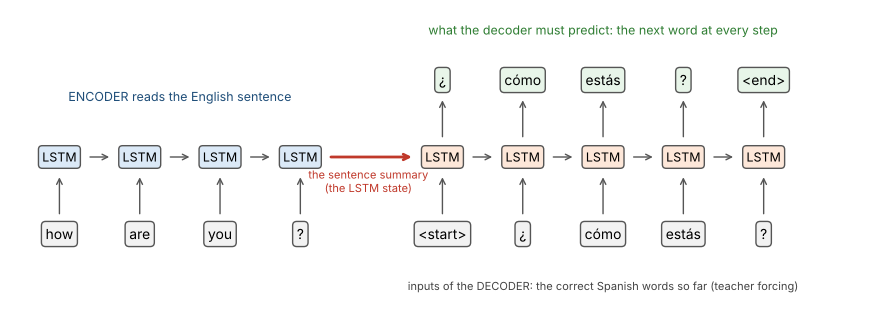

In [5]:
fig = tr.plot_seq2seq()
save_figure(fig, "01_seq2seq.png")
plt.show()

**What to notice.** Left, the encoder reads *how are you ?* and passes its state (red arrow) to the decoder. Right, the decoder gets `<start>` and must predict `¿`, then gets `¿` and must predict `cómo`, and so on until `<end>`.
During **training** we feed the decoder the *correct* previous word ("teacher forcing"), so all positions can be learned in parallel. At **translation** time there is no correct word to feed: the decoder has to use its *own* previous prediction. This difference between training and translation matters later.

*Figure: the encoder-decoder with teacher forcing.*

**Math (light).** At every step $t$ the decoder LSTM computes a state $h_t$ from its previous state, the word embedding of the previous word $y_{t-1}$ and, at the start, the encoder's summary. A softmax turns $h_t$ into probabilities for the next word:

$$p(y_t \mid y_1,\dots,y_{t-1},x) = \mathrm{softmax}(W h_t + b) \qquad \mathcal{L} = -\frac{1}{T}\sum_{t=1}^{T}\log p(y_t^{\text{true}}\mid y_1^{\text{true}},\dots,y_{t-1}^{\text{true}},x)$$

- $x$: the English sentence; $y_t$: the Spanish word at position $t$; $T$: the number of Spanish words (including `<end>`);
- $W$, $b$: the weights of the output layer (one row per Spanish word of the vocabulary: 8,000 rows);
- softmax: turns 8,000 scores into probabilities that add up to 1;
- $\mathcal{L}$: the loss: the average of $-\log$(probability given to the *right* next word). It is 0 if the model is sure of the right word and large if it gives it a low probability.

In [6]:
source, decoder_in, decoder_out = tr.encode_pairs(train_pairs, source_vocab, target_vocab)
val_source, val_decoder_in, val_decoder_out = tr.encode_pairs(validation_pairs, source_vocab, target_vocab)

k = 2
print("English  :", train_pairs[k][0], "->", source[k].tolist())
print("Spanish  :", train_pairs[k][1])
print("decoder gets  :", decoder_in[k].tolist(), [target_vocab.itos[i] for i in decoder_in[k] if i])
print("decoder wants :", decoder_out[k].tolist(), [target_vocab.itos[i] for i in decoder_out[k] if i])
print("arrays:", source.shape, decoder_in.shape, decoder_out.shape)

English  : Are you sure you want to do that? -> [28, 7, 338, 7, 37, 9, 20, 19, 11, 0]
Spanish  : ¿Estás seguro de que quieres hacer esto?
decoder gets  : [2, 7, 70, 257, 9, 11, 131, 56, 51, 6, 0] ['<start>', '¿', 'estás', 'seguro', 'de', 'que', 'quieres', 'hacer', 'esto', '?']
decoder wants : [7, 70, 257, 9, 11, 131, 56, 51, 6, 3, 0] ['¿', 'estás', 'seguro', 'de', 'que', 'quieres', 'hacer', 'esto', '?', '<end>']
arrays: (30001, 10) (30001, 11) (30001, 11)


**What to notice.** The English sentence is a row of numbers padded with 0 (`<pad>`) to 10 positions. The decoder's input is `<start>` followed by the Spanish words; what it must predict is the *same row shifted by one*, ending with `<end>` (number 3).
At every position the target is simply the next input. The zeros are ignored by the loss (`mask_zero=True` in the embedding layers).

In [7]:
tr.set_seed()
model, encoder, decoder = tr.build_seq2seq(len(source_vocab), len(target_vocab), embedding=128, units=256)
model.summary()

Model: "seq2seq"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ english             │ (None, 10)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spanish_so_far      │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embed_english       │ (None, 10, 128)   │    768,000 │ english[0][0]     │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 10)        │          0 │ english[0][0]     │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embed_spanish       │ (None, 1, 128)    │  1,024,000 │ spanish_so_far[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder (LSTM)      │ [(None, 256),     │    394,240 │ embed_english[0]… │
│                     │ (None, 256),      │            │ not_equal[0][0]   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder (LSTM)      │ [(None, 1, 256),  │    394,240 │ embed_spanish[0]… │
│                     │ (None, 256),      │            │ encoder[0][1],    │
│                     │ (None, 256)]      │            │ encoder[0][2]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, None, 256) │          0 │ decoder[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ next_word (Dense)   │ (None, 1, 8000)   │  2,056,000 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,636,480 (17.69 MB)

 Trainable params: 4,636,480 (17.69 MB)

 Non-trainable params: 0 (0.00 B)

**What to notice.** The model has 4,636,480 numbers to learn: about 2.06 million in the output layer (256 x 8,000 weights plus 8,000 offsets), 1.79 million in the two embedding tables (6,000 x 128 and 8,000 x 128) and 0.79 million in the two LSTMs (394,240 each). The 2023 model, with 1,024-unit recurrent layers and a 15,000-word softmax, was roughly eight times larger.
Note how the encoder returns its two state vectors ($h$ and $c$) and how the decoder receives them as its `initial_state`: that is the "summary" of the picture above.

### Check yourself

1. The encoder's state has 256 numbers in each of its two vectors. What does that imply for a sentence of 10 words?
2. Why does the decoder need `<start>`?

<details>
<summary>Answers</summary>


1. The whole sentence, however long, must be squeezed into 512 numbers: this "bottleneck" is the weak spot of this design, and it is what attention (the next notebook) addresses.
2. The decoder predicts each word from the previous one; for the first word there is no previous word, so a special start symbol plays its role.

</details>

## 6 · Training (CPU-sized)

30,000 training pairs, batches of 128, Adam with learning rate 0.002, at most 12 epochs (one epoch = every training pair once), seed 42. Training stops early if the validation loss does not improve for 2 epochs, and the best weights are kept.
The original script planned 15 epochs on about 97,000 pairs with 1,024-unit GRUs; that is too heavy for a CPU in a tutorial.

In [8]:
import keras

model.compile(optimizer=keras.optimizers.Adam(2e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)

start = time.time()
history = model.fit([source, decoder_in], decoder_out, batch_size=128, epochs=12,
                    validation_data=([val_source, val_decoder_in], val_decoder_out), callbacks=[stop], verbose=0).history
print(f"trained for {len(history['loss'])} epochs in {time.time() - start:.0f} s")
print("validation loss per epoch:", [round(v, 2) for v in history["val_loss"]])

trained for 12 epochs in 711 s
validation loss per epoch: [4.13, 3.8, 3.51, 3.25, 3.04, 2.9, 2.77, 2.67, 2.6, 2.53, 2.49, 2.45]


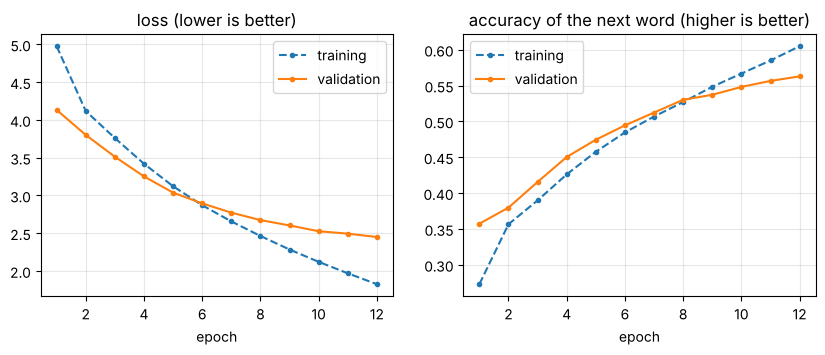

In [9]:
fig = tr.plot_training(history)
save_figure(fig, "01_training.png")
plt.show()

**What to notice** (figure and printed numbers):

- Training stopped after the **12 epochs allowed**; the early-stopping rule did not trigger because the validation loss was still falling slowly (2.53, 2.49 and 2.45 in the last three epochs). The model is **not fully trained**; more epochs (or data) would help.
- From about epoch 6 the two curves separate: at epoch 12 the training loss is about 1.8 against 2.45 for validation, and the next-word accuracy about 0.61 against 0.56. The model has started to fit the training sentences better than new ones.
- This accuracy is measured with the *correct* previous words given to the decoder (teacher forcing); it is much kinder than real translation, where one wrong word misleads the following ones.

*Figure: loss and next-word accuracy per epoch for the training and the validation sentences.*

## 7 · Translating sentences the model has never seen

Greedy decoding: encode the English sentence; then, starting from `<start>`, repeatedly take the *most probable next word* and feed it back as the next input, until `<end>`. The decoder is run one step at a time (a second model that shares the layers).
We translate the 2,000 test sentences and look at the first ones in the fixed test order, with one of the reference translations.

In [10]:
test_english = list(test)
test_source, _, _ = tr.encode_pairs([(e, "") for e in test_english], source_vocab, target_vocab)
references = [test[e] for e in test_english]

start = time.time()
hypotheses = tr.translate(encoder, decoder, test_source, target_vocab)
print(f"translated {len(test_english):,} sentences in {time.time() - start:.0f} s\n")

for english, hypothesis, reference in list(zip(test_english, hypotheses, references))[:12]:
    print(f"EN : {english}\nES : {' '.join(hypothesis)}\nREF: {reference[0]}\n")

translated 2,000 sentences in 5 s

EN : I bought two pairs of trousers.
ES : compré dos libros de la .
REF: Compré dos pares de pantalones.

EN : Tom died from tuberculosis.
ES : tom murió en el .
REF: Tom murió de tuberculosis.

EN : Will it be hot again tomorrow?
ES : ¿ de verdad te bien ?
REF: ¿Mañana volverá a hacer calor?

EN : I don't know how to swim.
ES : no sé cómo .
REF: No sé nadar.

EN : Tom stabbed Mary repeatedly with his knife.
ES : tom ayudó a mary con su padre .
REF: Tom apuñaló a Mary repetidamente con su cuchillo.

EN : I don't remember inviting you.
ES : no me acuerdo con él .
REF: No recuerdo haberte invitado.

EN : Where did you buy this motorcycle?
ES : ¿ dónde aprendiste a tu auto ?
REF: ¿Dónde compraste esta moto?

EN : What else do you want to do?
ES : ¿ qué quieres hacer eso ?
REF: ¿Qué más quieres hacer?

EN : There are many theories about the origin of life.
ES : hay muchas personas el año pasado .
REF: Hay mucha teorías sobre el origen de la vida.

EN : Do

**What to notice.** The output is Spanish-looking, with accents and with the right start of the sentence now and then, but **often wrong in content**:

- *I bought two pairs of trousers.* became *compré dos libros de la .*: "I bought two" is right, "books" is wrong. *Tom died from tuberculosis.* became *tom murió en el .*: "Tom died" is right.
- Some translations are fluent but about something else: *There are many theories about the origin of life.* became *hay muchas personas el año pasado .*; *Will it be hot again tomorrow?* became *¿ de verdad te bien ?*.
- *I feel so lonely.* became *me siento tan cansada .* ("tired" instead of "lonely"): the model writes a frequent phrase with a similar shape.
- Words the model predicts as `<unk>` are dropped from the printout, which explains the gaps (*en el .*).

This is what a small model trained on 30,000 pairs for twelve epochs does: it has learned the shape of Spanish sentences and some frequent words, not the meaning of most English sentences.

*Printout: the first twelve test sentences in the fixed test order, with the first reference translation.*

## 8 · A real measure: BLEU

**BLEU** (Papineni et al., 2002) compares a translation with reference translations by counting the *n-grams* (runs of 1 to 4 words) that they share, with a penalty for translations that are too short. It goes from 0 to 100.
Our test sentences often have several valid Spanish translations, so we use all of them (up to the number available) as references. Our texts are lower-case and split into words and punctuation marks; **the scores are therefore not comparable with BLEU numbers from papers**,
which use detokenised text, other data and bigger models. We also report the **exact match rate** (the translation equals one of the references) and a **floor** for context: "translating" by copying the English words.

In [11]:
bleu = tr.corpus_bleu(hypotheses, references)
exact = np.mean([" ".join(h) in [" ".join(tr.tokenize(r)) for r in refs] for h, refs in zip(hypotheses, references)])
copy_floor = tr.corpus_bleu([tr.tokenize(e) for e in test_english], references)
length_ratio = np.mean([len(h) / np.mean([len(tr.tokenize(r)) for r in refs]) for h, refs in zip(hypotheses, references)])
repeated = np.mean([any(h[i:i + 2] == h[j:j + 2] for i in range(len(h) - 1) for j in range(i + 2, len(h) - 1)) for h in hypotheses])

print(f"BLEU of the model          : {bleu:5.1f}")
print(f"BLEU of copying the English: {copy_floor:5.1f}   (a floor, not a translation)")
print(f"exact match                : {exact:.1%}")
print(f"average length (translation / reference): {length_ratio:.2f}")
print(f"translations that repeat a pair of words: {repeated:.1%}")

BLEU of the model          :  11.2
BLEU of copying the English:   0.3   (a floor, not a translation)
exact match                : 1.8%
average length (translation / reference): 0.92
translations that repeat a pair of words: 1.2%


1-4 words     159 sentences   BLEU 14.4
5-7 words    1092 sentences   BLEU 12.0
8-10 words    749 sentences   BLEU 10.3


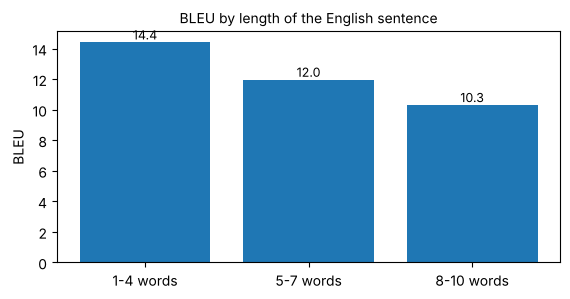

In [12]:
groups = [("1-4 words", 1, 4), ("5-7 words", 5, 7), ("8-10 words", 8, 10)]
scores, sizes = [], []
for label, low, high in groups:
    index = [i for i, e in enumerate(test_english) if low <= len(tr.tokenize(e)) <= high]
    scores.append(tr.corpus_bleu([hypotheses[i] for i in index], [references[i] for i in index])); sizes.append(len(index))
    print(f"{label:11s} {len(index):5d} sentences   BLEU {scores[-1]:.1f}")
fig = tr.plot_bars([g[0] for g in groups], scores, "BLEU by length of the English sentence")
save_figure(fig, "01_bleu_by_length.png")
plt.show()

**What to notice.**

- **BLEU 11.2**, against 0.3 for copying the English words: the model is far above the floor, and far from a usable translator. The **exact match rate is 1.8%**.
- Translations are slightly **shorter** than the references (length ratio 0.92), and only 1.2% repeat a pair of words, so the repetition loops known from greedy decoding are rare here.
- **BLEU falls with the length of the English sentence:** 14.4 for 1-4 words, 12.0 for 5-7 and 10.3 for 8-10. This is consistent with the idea that squeezing the whole sentence into one state hurts long sentences, but it is not proof: longer sentences also contain more words that can go wrong.
- All numbers come from one training run with one seed on 2,000 test sentences; differences of a point or so between models should not be over-interpreted. These numbers are the baseline for the next notebooks.

*Figure: BLEU of the model by length of the English sentence.*

## 9 · Common mistakes (and where the 2023 script made them)

- **Building the vocabulary from the wrong split** (or from all the data). It leaks information about the test data.
- **Splitting pairs at random when sentences repeat.** The test then contains sentences the model has seen. Split by the source sentence.
- **Deleting characters that carry meaning.** Accents are part of Spanish words; a "clean" text that removes them is a different language.
- **Training without ever translating.** Training accuracy says little about translation quality; always look at translations and compute a metric on unseen sentences.
- **Reading BLEU as a percentage of correct sentences.** It is a similarity score of n-grams; only compare scores computed in the same way on the same data.

## 10 · Recap

- An encoder-decoder reads a sentence into a state and writes the translation word by word; training feeds the correct previous word, translation feeds its own.
- With a leak-free split and a CPU-sized model, the baseline produces fluent-looking Spanish but often the wrong content; the numbers above are the bar for the next parts.
- All of the sentence has to pass through one small state; attention (next notebook) lets the decoder look back at the English words instead.

**Next:** notebook 02 adds attention to the same model, on the same split, and shows a heat map of what the decoder looks at.